# Fase 1 — Análisis Exploratorio (EDA) y Selección de Predictores

**Objetivo:** Explorar la distribución de la variable respuesta (ASRS), analizar su relación lineal con variables candidatas mediante gráficas de dispersión y correlación de Pearson ($r$), y proponer 3–4 predictores con sentido clínico y sin multicolinealidad.

**Variable respuesta ($Y$):** ASRS (Adult ADHD Self-Report Scale), puntaje de 0 a 72 que mide la severidad autorreportada de síntomas de TDAH en adultos.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_csv("../data/processed/hyperaktiv_arc_clean.csv")
FIG_DIR = Path("../reports/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)

print(df.shape)
print(df.columns[:40].tolist())

(75, 885)
['ID', 'SEX', 'AGE', 'ACC', 'ACC_TIME', 'ACC_DAYS', 'HRV', 'HRV_TIME', 'HRV_HOURS', 'CPT_II', 'ADHD', 'ADD', 'BIPOLAR', 'UNIPOLAR', 'ANXIETY', 'SUBSTANCE', 'OTHER', 'CT', 'MDQ_POS', 'WURS', 'ASRS', 'MADRS', 'HADS_A', 'HADS_D', 'MED', 'MED_Antidepr', 'MED_Moodstab', 'MED_Antipsych', 'MED_Anxiety_Benzo', 'MED_Sleep', 'MED_Analgesics_Opioids', 'MED_Stimulants', 'filter_$', 'Assessment Status', 'Assessment Duration', 'Type', 'LastTrial', 'General TScore Omissions', 'Adhd TScore Omissions', 'Neuro TScore Omissions']


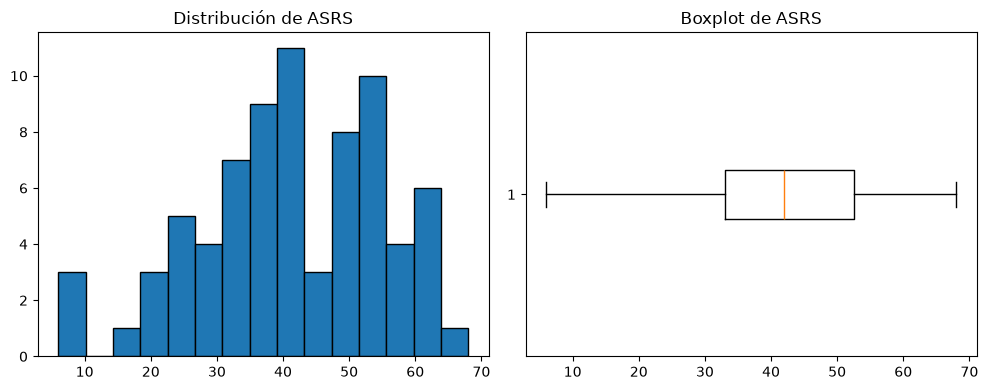

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].hist(df["ASRS"], bins=15, edgecolor="black"); ax[0].set_title("Distribución de ASRS")
ax[1].boxplot(df["ASRS"], orientation="horizontal"); ax[1].set_title("Boxplot de ASRS")
plt.tight_layout(); plt.savefig(FIG_DIR / "asrs_distribucion.png", dpi=150); plt.show()

## Distribución de ASRS

- $n = 75$ pacientes, rango de 6 a 68, media ≈ 41.4, mediana = 42, desviación estándar ≈ 13.9.
- La distribución es aproximadamente simétrica con una ligera cola a la izquierda (un pequeño grupo de 3 pacientes con puntajes muy bajos, entre 6 y 10).
- El boxplot no muestra valores atípicos: los bigotes abarcan todas las observaciones.
- La media y la mediana son muy cercanas, lo que sugiere que no hay un sesgo fuerte que obligue a transformar $Y$ de entrada.

In [6]:
from scipy.stats import pearsonr

tscores = [c for c in df.columns if "TScore" in c]
candidatas = ["AGE", "WURS", "MADRS", "HADS_A", "HADS_D"] + tscores

filas = []
for c in candidatas:
    d = df[[c, "ASRS"]].dropna()
    r, p = pearsonr(d[c], d["ASRS"])
    filas.append({"variable": c, "r": round(r, 3), "p_valor": round(p, 4), "n": len(d)})

corr = pd.DataFrame(filas).sort_values("r", key=abs, ascending=False)
display(corr)

,variable,r,p_valor,n
1,WURS,0.685,0.0000,74
9,Adhd TScore Commissions,0.528,0.0000,75
8,General TScore Commissions,0.526,0.0000,75
10,Neuro TScore Commissions,0.482,0.0000,75
21,Adhd TScore DPrime,0.405,0.0003,75
20,General TScore DPrime,0.398,0.0004,75
22,Neuro TScore DPrime,0.357,0.0016,75
17,General TScore VarSE,0.314,0.0061,75
3,HADS_A,0.304,0.0111,69
19,Neuro TScore VarSE,0.303,0.0082,75


## Correlación de Pearson ($r$) con ASRS

Se excluyeron `ID`, las variables binarias y los diagnósticos `ADHD` y `ADD` para evitar fuga de información (son el diagnóstico mismo).

- **WURS** ($r = 0.685$, $p < 0.001$): correlación positiva fuerte. Más síntomas de TDAH en la infancia se asocian con mayor severidad en la adultez, lo cual es coherente con que el TDAH es un trastorno del neurodesarrollo que inicia en la infancia.
- **TScore Commissions** ($r \approx 0.53$, $p < 0.001$): correlación positiva moderada. Las comisiones son errores de impulsividad en el CPT-II (responder cuando no se debía).
- **TScore DPrime** ($r \approx 0.40$, $p < 0.001$): correlación positiva moderada.
- **HADS_A** ($r = 0.304$, $p = 0.011$): correlación positiva débil-moderada pero significativa; la ansiedad es una comorbilidad frecuente del TDAH.
- **MADRS, HADS_D y AGE**: no significativas ($p > 0.05$); no muestran relación lineal con ASRS.

**Nota:** Las versiones *Adhd*, *General* y *Neuro* de cada T-score del CPT-II son la misma medida comparada contra distintos grupos normativos, por lo que se usa solo la versión *General*.

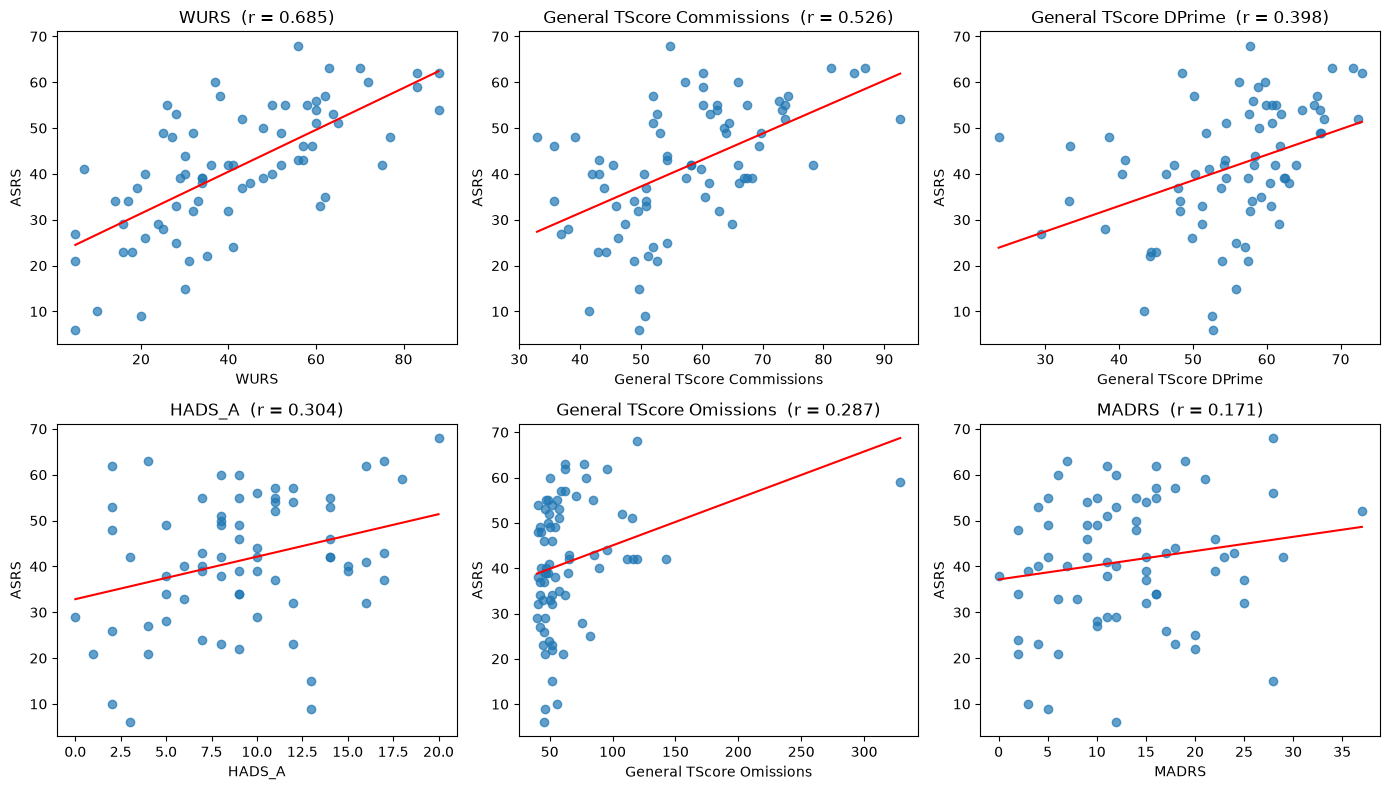

In [7]:
import numpy as np
TAB_DIR = Path("../reports/tables"); TAB_DIR.mkdir(parents=True, exist_ok=True)
corr.to_csv(TAB_DIR / "correlaciones_asrs.csv", index=False)

top = ["WURS", "General TScore Commissions", "General TScore DPrime",
       "HADS_A", "General TScore Omissions", "MADRS"]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, c in zip(axes.flat, top):
    d = df[[c, "ASRS"]].dropna()
    ax.scatter(d[c], d["ASRS"], alpha=0.7)
    m, b = np.polyfit(d[c], d["ASRS"], 1)
    xs = np.linspace(d[c].min(), d[c].max(), 100)
    ax.plot(xs, m*xs + b, color="red")
    r = corr.loc[corr["variable"] == c, "r"].values[0]
    ax.set_title(f"{c}  (r = {r})"); ax.set_xlabel(c); ax.set_ylabel("ASRS")
plt.tight_layout(); plt.savefig(FIG_DIR / "dispersion_candidatas.png", dpi=150); plt.show()

## Gráficas de dispersión

- **WURS:** relación claramente lineal y positiva, con dispersión homogénea a lo largo del eje (sin forma de embudo).
- **Commissions:** tendencia lineal positiva, con mayor dispersión que WURS.
- **DPrime:** tendencia positiva pero más dispersa.
- **HADS_A:** relación débil, nube muy dispersa con pendiente leve.
- **Omissions:** la mayoría de los valores se concentra entre 40 y 100, y un solo paciente con valor ≈ 330 jala la línea de tendencia. Su $r = 0.287$ está inflado por este punto influyente, por lo que se descarta.
- **MADRS:** nube sin tendencia; se incluye como contraste de una variable sin relación lineal.

Esto muestra la importancia de complementar el coeficiente $r$ con el análisis gráfico.

In [8]:
display(df[top[:5]].corr().round(2))

,WURS,General TScore Commissions,General TScore DPrime,HADS_A,General TScore Omissions
WURS,1.00,0.47,0.38,0.41,0.36
General TScore Commissions,0.47,1.00,0.88,0.16,0.18
General TScore DPrime,0.38,0.88,1.00,0.14,0.17
HADS_A,0.41,0.16,0.14,1.00,0.30
General TScore Omissions,0.36,0.18,0.17,0.30,1.00


## Selección preliminar de predictores

La matriz de correlación entre candidatas muestra que **Commissions y DPrime tienen $r = 0.88$**, lo que indica multicolinealidad: miden prácticamente lo mismo. Se conserva Commissions por su mayor correlación con ASRS. Las demás combinaciones tienen $|r| \le 0.47$.

**Predictores propuestos:**

| Variable | Qué mide | $r$ con ASRS |
|---|---|---|
| WURS | Síntomas de TDAH en la infancia | 0.685 |
| General TScore Commissions | Impulsividad (CPT-II) | 0.526 |
| HADS_A | Ansiedad | 0.304 |

Esta combinación cubre tres dimensiones complementarias: historia clínica, desempeño objetivo en una prueba de atención y comorbilidad emocional. La confirmación final depende del VIF (< 5) calculado en la fase conjunta.